# ANN with TF-Keras

In [108]:
!python --version

Python 3.13.15


In [109]:
!pip list | grep tensorflow

tensorflow                            2.21.0
tensorflow-datasets                   4.9.10
tensorflow-hub                        0.16.1
tensorflow-metadata                   1.21.0
tensorflow-probability                0.25.0
tensorflow-text                       2.21.1


In [110]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential, load_model
from keras.layers import Dense, Flatten
from keras.datasets import mnist, fashion_mnist
import numpy as np
import matplotlib.pyplot as plt

In [111]:
tf.__version__

'2.21.0'

In [112]:
keras.__version__

'3.13.2'

## Load Dataset from keras

In [113]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [114]:
# (X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

In [115]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [116]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [117]:
X_train.dtype

dtype('uint8')

In [118]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

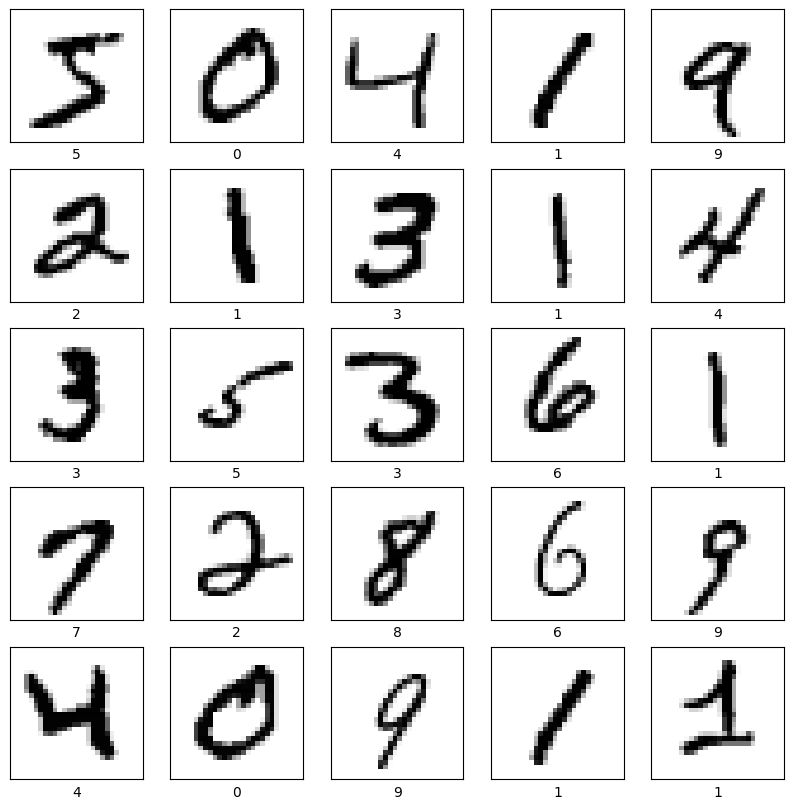

In [119]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(y_train[i])
    plt.imshow(X_train[i], cmap=plt.cm.binary)

In [120]:
# Normalization
X_train = X_train / 255.0
X_test = X_test / 255.0

In [121]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [122]:
y_train[0]

np.uint8(5)

## Model

In [123]:
model = Sequential()
model.add(Flatten(input_shape=(28,28)))
model.add(Dense(100, activation='relu', name='hidden_layer_1'))
model.add(Dense(10, activation='softmax', name='output_layer'))





In [124]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_1 (Dense)          │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [125]:
from keras.utils import plot_model
# plot_model(model, show_shapes=True, show_layer_names=True)

In [126]:
hidden_layer = model.layers[1]
hidden_layer.name

'hidden_layer_1'

In [127]:
h1 = model.get_layer('hidden_layer_1')
h1

<Dense name=hidden_layer_1, built=True>

In [128]:
h1.name

'hidden_layer_1'

In [129]:
weights, biases = h1.get_weights()
weights.shape, weights, biases.shape, biases

((784, 100),
 array([[-0.01198175,  0.08092865,  0.06168467, ..., -0.06563689,
         -0.080601  , -0.07661431],
        [ 0.0388427 , -0.07971796, -0.01462399, ..., -0.05199514,
         -0.04921736,  0.08050957],
        [-0.0473016 , -0.01927818, -0.07070777, ...,  0.01364273,
         -0.00305028,  0.08198202],
        ...,
        [ 0.04073724,  0.00245222, -0.01289815, ..., -0.01967721,
         -0.02556977, -0.0744431 ],
        [-0.06925122, -0.03640711, -0.07208989, ...,  0.01259896,
         -0.02759645, -0.02089169],
        [ 0.04176608, -0.02771633,  0.04664519, ...,  0.05975872,
         -0.05086114, -0.01412255]], dtype=float32),
 (100,),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 

In [130]:
output_layer = model.get_layer('output_layer')
output_layer

<Dense name=output_layer, built=True>

## Manual weight assignments

In [131]:
# new_weights = np.ones_like(weights)
# new_weights.shape, new_weights

In [132]:
# h1.set_weights([new_weights, biases])

In [133]:
# h1.get_weights()

## Training

In [134]:
# Compile
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [135]:
history = model.fit(X_train,
          y_train,
          epochs=10,
          validation_split=0.2,
          verbose=True)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9131 - loss: 0.3053 - val_accuracy: 0.9508 - val_loss: 0.1701
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9599 - loss: 0.1386 - val_accuracy: 0.9610 - val_loss: 0.1312
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9716 - loss: 0.0969 - val_accuracy: 0.9645 - val_loss: 0.1187
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9782 - loss: 0.0733 - val_accuracy: 0.9692 - val_loss: 0.1035
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9827 - loss: 0.0572 - val_accuracy: 0.9730 - val_loss: 0.0915
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9862 - loss: 0.0457 - val_accuracy: 0.9744 - val_loss: 0.0903
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9886 - loss: 0.0368 - val_accuracy: 0.9764 - val_loss: 0.0840
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9909 - loss: 0.0304 -

In [136]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9788 - loss: 0.0786


[0.07855243235826492, 0.9787999987602234]

In [137]:
h1.get_weights()

[array([[-0.01198175,  0.08092865,  0.06168467, ..., -0.06563689,
         -0.080601  , -0.07661431],
        [ 0.0388427 , -0.07971796, -0.01462399, ..., -0.05199514,
         -0.04921736,  0.08050957],
        [-0.0473016 , -0.01927818, -0.07070777, ...,  0.01364273,
         -0.00305028,  0.08198202],
        ...,
        [ 0.04073724,  0.00245222, -0.01289815, ..., -0.01967721,
         -0.02556977, -0.0744431 ],
        [-0.06925122, -0.03640711, -0.07208989, ...,  0.01259896,
         -0.02759645, -0.02089169],
        [ 0.04176608, -0.02771633,  0.04664519, ...,  0.05975872,
         -0.05086114, -0.01412255]], dtype=float32),
 array([ 0.00715007,  0.00815759,  0.00783737,  0.07322866, -0.07090207,
         0.25958744,  0.08895554, -0.115514  , -0.05155085,  0.17666313,
         0.03581567, -0.05533796,  0.08579707,  0.0510151 ,  0.09134769,
         0.08378058,  0.15756379,  0.01794743, -0.01456659, -0.026767  ,
         0.01521377, -0.0729923 ,  0.07330151, -0.02662374,  0.056

## Visualization

In [138]:
history.history

{'accuracy': [0.9131458401679993,
  0.9599166512489319,
  0.9716041684150696,
  0.9781666398048401,
  0.9827083349227905,
  0.9862083196640015,
  0.9886249899864197,
  0.9908750057220459,
  0.9926249980926514,
  0.9934791922569275],
 'loss': [0.30532899498939514,
  0.13857519626617432,
  0.09687928110361099,
  0.07328606396913528,
  0.05721807852387428,
  0.04568258300423622,
  0.03684860095381737,
  0.030426980927586555,
  0.02467671036720276,
  0.02168758399784565],
 'val_accuracy': [0.9508333206176758,
  0.9610000252723694,
  0.9645000100135803,
  0.9691666960716248,
  0.9729999899864197,
  0.9744166731834412,
  0.9764166474342346,
  0.9736666679382324,
  0.9752500057220459,
  0.9750000238418579],
 'val_loss': [0.17014996707439423,
  0.13121338188648224,
  0.11874270439147949,
  0.10351482033729553,
  0.09154503047466278,
  0.09025897085666656,
  0.0840262845158577,
  0.09292343258857727,
  0.09059689193964005,
  0.08770223706960678]}

In [139]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

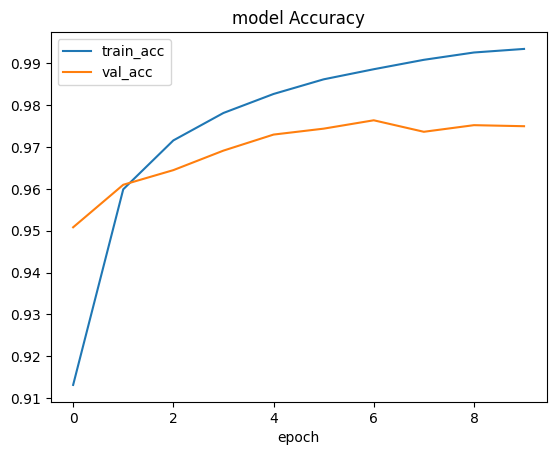

In [140]:
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')

plt.title('model Accuracy')

plt.xlabel('epoch')
plt.legend()

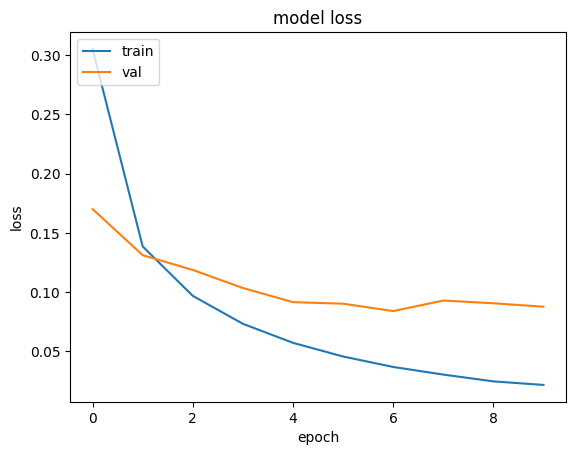

In [141]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

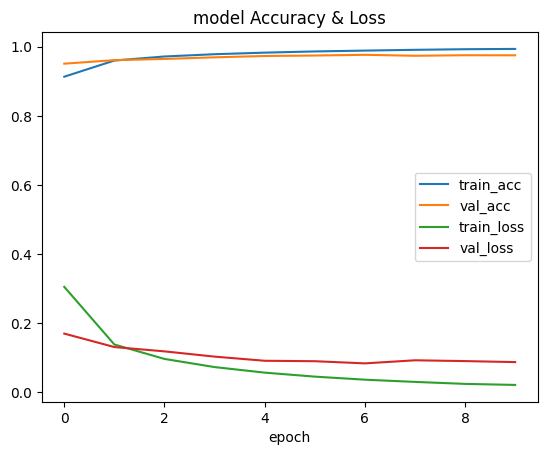

In [142]:
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('model Accuracy & Loss')

plt.xlabel('epoch')
plt.legend()

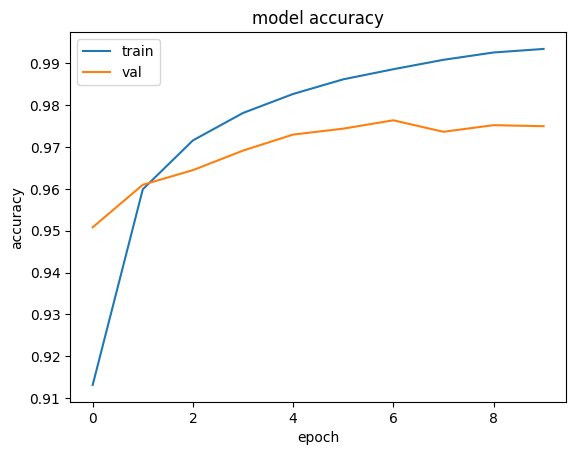

In [143]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')